# Model 1 v3 – 08 Unseen-source test (v2 vs v3)
**Purpose:** Check that v3 fixes the "photo of a body part accepted as X-ray" problem WITHOUT breaking anything:
(1) the same unseen suite as v2 (notebook 05: PneumoniaMNIST chest X-rays, CT, retina, flowers, documents, edge cases),
(2) real-world folders in UNSEEN_TEST/ that were never used for training.
**Inputs:** outputs/model1_v2/unseen_suite_v1.npz + v2 models, outputs/model1_v3/ (v3 models), UNSEEN_TEST/
**Outputs:** outputs/model1_v3/unseen_results_v2_vs_v3.csv, unseen_summary_v2_vs_v3.csv
**Privacy:** real-world photos are only listed by file name, never plotted (notebooks are committed to GitHub).

In [1]:
# ===== SETTINGS =====
from pathlib import Path
DRIVE_ROOT = Path('/content/drive/MyDrive/Research')
V2_DIR     = DRIVE_ROOT / 'outputs' / 'model1_v2'
OUT_DIR    = DRIVE_ROOT / 'outputs' / 'model1_v3'
UNSEEN_DIR = DRIVE_ROOT / 'UNSEEN_TEST'
SUITE      = V2_DIR / 'unseen_suite_v1.npz'          # saved by notebook 05 (identical images)

# real-world folders inside UNSEEN_TEST and the correct answer for each (missing folders are skipped)
UNSEEN_FOLDERS = {'Dental_xray_photos': 'X_RAY',     # policy: a photo of an X-ray counts as an X-ray
                  'Xray_photos_real':   'X_RAY',     # phone photos of real X-ray films/screens
                  'Body_photos':        'NON_XRAY'}  # photos of hands, feet, legs, arms, people (internet / own)
LOW, HIGH = 0.3, 0.7                                 # three-way gate, fixed in notebook 05

In [2]:
!pip install -q timm
from google.colab import drive
drive.mount('/content/drive')
import numpy as np, pandas as pd, torch, torch.nn as nn, timm, matplotlib.pyplot as plt
from PIL import Image, ImageOps
from torchvision.models import mobilenet_v3_large
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

Mounted at /content/drive
Device: cuda


## Step 1 – Load the unseen suite (same images as notebook 05) + real-world folders

In [3]:
IMG_SIZE = 224

def prep_pil(im):                                   # identical to the v2 data preparation (notebook 03)
    im = ImageOps.exif_transpose(im)
    if im.mode in ('I;16', 'I;16B', 'I;16L', 'I', 'F'):
        a = np.asarray(im, dtype=np.float32); a = (a - a.min()) / max(a.max() - a.min(), 1) * 255
        im = Image.fromarray(a.astype(np.uint8))
    if im.mode == 'P': im = im.convert('RGBA')
    if im.mode in ('RGBA', 'LA'):
        bg = Image.new('RGBA', im.size, (0, 0, 0, 255)); im = Image.alpha_composite(bg, im.convert('RGBA'))
    im = im.convert('L'); w, h = im.size; s = max(w, h)
    canvas = Image.new('L', (s, s), 0); canvas.paste(im, ((s - w) // 2, (s - h) // 2))
    return np.asarray(canvas.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)

s = np.load(SUITE, allow_pickle=True)
all_imgs, all_groups, all_expected = list(s['images']), list(s['group']), list(s['expected'])
all_files = [''] * len(all_imgs)
print('Unseen suite (from notebook 05):', len(all_imgs), 'images')
for folder, exp in UNSEEN_FOLDERS.items():
    d = UNSEEN_DIR / folder
    if not d.exists(): print(f'{folder}: folder not found - skipped'); continue
    files = sorted(p for p in d.glob('*') if p.is_file())
    for p in files:
        with Image.open(p) as im:
            all_imgs.append(prep_pil(im)); all_groups.append(f'REAL_{folder}'); all_expected.append(exp); all_files.append(p.name)
    print(f'{folder}: {len(files)} images (expected {exp})')
all_imgs = np.stack(all_imgs)
print('Total:', len(all_imgs))

Unseen suite (from notebook 05): 250 images
Dental_xray_photos: 11 images (expected X_RAY)
Xray_photos_real: 2 images (expected X_RAY)
Body_photos: 25 images (expected NON_XRAY)
Total: 288


## Step 2 – Predict with v2 and v3 (both ensembles + members)

In [4]:
def load_ck(path):
    ck = torch.load(path, map_location=device)
    if ck['timm_name'] == 'torchvision':
        m = mobilenet_v3_large(); m.classifier[3] = nn.Linear(m.classifier[3].in_features, 2)
    else:
        m = timm.create_model(ck['timm_name'], pretrained=False, num_classes=2)
    m.load_state_dict(ck['state_dict']); return m.eval().to(device), ck['mean'], ck['std']

@torch.no_grad()
def p_xray(model, mean, std, arr):
    mean = torch.tensor(mean).view(1, 3, 1, 1).to(device); std = torch.tensor(std).view(1, 3, 1, 1).to(device)
    out = []
    for k in range(0, len(arr), 64):
        t = torch.from_numpy(arr[k:k+64]).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(device)
        out.append(torch.softmax(model((t - mean) / std), 1)[:, 1].cpu().numpy())
    return np.concatenate(out)

res = pd.DataFrame({'group': all_groups, 'expected': all_expected, 'file': all_files})
for v, d, tag in [('v2', V2_DIR, 'model1v2'), ('v3', OUT_DIR, 'model1v3')]:
    res[f'{v} MobileNetV3'] = p_xray(*load_ck(d / f'mobilenetv3_{tag}_best.pt'), all_imgs)
    res[f'{v} DeiT-Small']  = p_xray(*load_ck(d / f'deit_small_{tag}_best.pt'), all_imgs)
    res[f'{v} Ensemble'] = (res[f'{v} MobileNetV3'] + res[f'{v} DeiT-Small']) / 2
res.to_csv(OUT_DIR / 'unseen_results_v2_vs_v3.csv', index=False)
print('Saved predictions for', len(res), 'images')

Saved predictions for 288 images


## Step 3 – Results per group (% correct at 0.5) and the three-way gate

In [5]:
MODELS_ = ['v2 MobileNetV3', 'v2 DeiT-Small', 'v2 Ensemble', 'v3 MobileNetV3', 'v3 DeiT-Small', 'v3 Ensemble']
rows = []
for (g, exp), sub in res.groupby(['group', 'expected'], sort=False):
    row = {'group': g, 'expected': exp, 'n': len(sub)}
    for m in MODELS_:
        share_x = (sub[m] >= 0.5).mean()
        row[m] = round(100 * (1 - share_x if exp == 'NON_XRAY' else share_x), 1)
    rows.append(row)
table = pd.DataFrame(rows)
print('Values = % CORRECT (for "unclear" edge cases: % accepted as X-ray)\n')
print(table.to_string(index=False))
table.to_csv(OUT_DIR / 'unseen_summary_v2_vs_v3.csv', index=False)

known = res[res.expected != 'unclear']; y_true = (known.expected == 'X_RAY').values
print(f'\nKnown images: {len(known)}  |  three-way gate: >= {HIGH} X-ray, < {LOW} not X-ray, else uncertain')
for m in MODELS_:
    p = known[m].values; acc, rej = p >= HIGH, p < LOW; unc = ~acc & ~rej
    wrong = (acc & ~y_true) | (rej & y_true)
    print(f'  {m:15s}: correct@0.5 {((p >= 0.5) == y_true).mean():6.1%} | gate: wrong {wrong.sum():2d}, uncertain {unc.sum():2d}')

Values = % CORRECT (for "unclear" edge cases: % accepted as X-ray)

                       group expected  n  v2 MobileNetV3  v2 DeiT-Small  v2 Ensemble  v3 MobileNetV3  v3 DeiT-Small  v3 Ensemble
   chest_xray_PneumoniaMNIST    X_RAY 60           100.0          100.0        100.0           100.0          100.0        100.0
      CT_coronal_OrganCMNIST NON_XRAY 50            94.0           96.0         94.0            94.0           98.0         98.0
    retina_photo_RetinaMNIST NON_XRAY 40            97.5           87.5         95.0            92.5           97.5         95.0
     flower_photo_Flowers102 NON_XRAY 40            92.5           92.5         92.5            97.5          100.0        100.0
     text_document_synthetic NON_XRAY 20           100.0          100.0        100.0           100.0          100.0        100.0
          EDGE_inverted_xray  unclear 20           100.0          100.0        100.0           100.0          100.0        100.0
EDGE_photo_of_xray_simulated 

## Step 4 – Real-world images one by one (file names only, no pictures)

In [6]:
real = res[res.group.str.startswith('REAL_')]
cols = ['group', 'file', 'expected', 'v2 Ensemble', 'v3 Ensemble']
def decide(p): return 'X-ray' if p >= HIGH else 'not X-ray' if p < LOW else 'uncertain'
out = real[cols].copy()
out['v2 decision'] = out['v2 Ensemble'].map(decide); out['v3 decision'] = out['v3 Ensemble'].map(decide)
print(out.round(3).to_string(index=False))

                  group                                     file expected  v2 Ensemble  v3 Ensemble v2 decision v3 decision
REAL_Dental_xray_photos                        xray_dental1.jpeg    X_RAY        0.850        0.587       X-ray   uncertain
REAL_Dental_xray_photos                       xray_dental10.jpeg    X_RAY        0.956        0.861       X-ray       X-ray
REAL_Dental_xray_photos                       xray_dental11.jpeg    X_RAY        0.994        0.478       X-ray   uncertain
REAL_Dental_xray_photos                        xray_dental2.jpeg    X_RAY        1.000        0.803       X-ray       X-ray
REAL_Dental_xray_photos                        xray_dental3.jpeg    X_RAY        0.978        0.190       X-ray   not X-ray
REAL_Dental_xray_photos                        xray_dental4.jpeg    X_RAY        1.000        0.873       X-ray       X-ray
REAL_Dental_xray_photos                        xray_dental5.jpeg    X_RAY        0.963        0.939       X-ray       X-ray
REAL_Den

## Step 5 – Remaining v3 mistakes on the public unseen suite (real-world photos are not shown)

v3 ensemble mistakes (public suite): 3


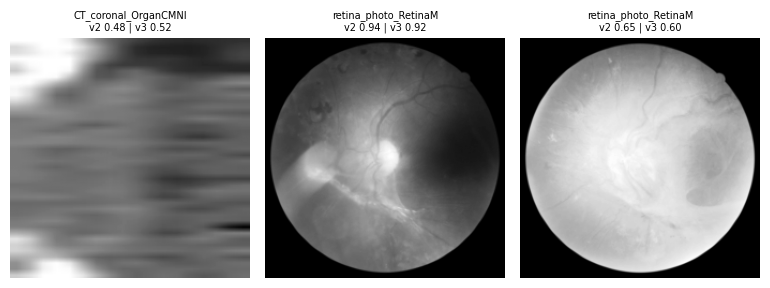

In [7]:
wrong = res[(res.expected != 'unclear') & ~res.group.str.startswith('REAL_')
            & ((res['v3 Ensemble'] >= 0.5) != (res.expected == 'X_RAY'))]
print('v3 ensemble mistakes (public suite):', len(wrong))
if len(wrong):
    show = wrong.head(12)
    fig, axes = plt.subplots(1, len(show), figsize=(2.6 * len(show), 3.2)); axes = np.atleast_1d(axes)
    for ax, (i, r) in zip(axes, show.iterrows()):
        ax.imshow(all_imgs[i], cmap='gray'); ax.axis('off')
        ax.set_title(f'{r.group[:20]}\nv2 {r["v2 Ensemble"]:.2f} | v3 {r["v3 Ensemble"]:.2f}', fontsize=7)
    plt.tight_layout(); plt.show()

## Summary – Model 1 v3 unseen-source test (248 known + 40 edge-case images)
| Group | v2 Ensemble | v3 Ensemble |
|---|---|---|
| Chest X-ray (PneumoniaMNIST, 60) | 100 | 100 |
| CT (OrganCMNIST, 50) | 94.0 | 98.0 |
| Retina photo (40) | 95.0 | 95.0 |
| Flower photo (40) | 92.5 | 100 |
| Text document (20) | 100 | 100 |
| Real dental X-ray phone photos (11) | 100 | 81.8 |
| Real X-ray phone photos (knee, 2) | 100 | 100 |
| NEW: Body photos from internet (25) | 36.0 | 92.0 |
| **Overall (known, 248)** | **90.3** | **97.2** |
Three-way gate: v2 ensemble 16 wrong / 16 uncertain → v3 ensemble 2 wrong / 14 uncertain.
Body photos accepted as X-ray: v2 16/25 → v3 0/25 (21 rejected, 4 uncertain).
Trade-off: v3 is more cautious on phone photos of X-rays (dental: 5 accepted, 5 uncertain, 1 rejected);
dental = 1 patient, ~3–4 X-rays → small sample; photo-of-X-ray policy still to be agreed with the team.
Remaining wrong decisions: 1 retina photo accepted (p 0.92, same as v2), 1 dental photo rejected (p 0.19).
**Final Model 1 = v3 ensemble (MobileNetV3 + DeiT-Small) with the same three-way gate.**